# ĐỒ ÁN TỐT NGHIỆP: NGHIÊN CỨU XÂY DỰNG MÔ HÌNH MACHINE LEARNING TRONG ĐÁNH GIÁ VÀ DỰ BÁO RỦI RO TÍN DỤNG KHÁCH HÀNG

## Giai đoạn 1: Data Audit & Exploratory Data Analysis (EDA)
**Dataset**: UCI Credit Card Default Dataset (`UCI_Credit_Card.csv`)  
**Tác giả**: Sinh viên ĐATN  
**Mục tiêu Notebook**:
- Thực hiện kiểm tra toàn diện dữ liệu (Data Integrity Audit, Data Leakage Check).
- Thống kê mô tả chi tiết 25 biến dữ liệu (Demographic, Payment Status, Bill Amount, Pay Amount, Target).
- Trực quan hóa phân bố, phát hiện giá trị bất thường (Anomalies/Outliers), hiện tượng mất cân bằng lớp (Class Imbalance) và đa cộng tuyến (Multicollinearity).
- **Lưu ý**: Notebook chỉ tập trung phân tích và đưa ra đề xuất Preprocessing, tuyệt đối không huấn luyện mô hình ML hoặc tự ý thay đổi dữ liệu khi chưa giải thích rõ.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image, Markdown

# Cấu hình hiển thị
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

print("Đã tải xong các thư viện cần thiết.")


Đã tải xong các thư viện cần thiết.


---
## 1. Đọc và Kiểm tra Cấu trúc Dữ liệu Tổng quan (Dataset Structure Overview)

Chúng ta tiến hành đọc file `data/UCI_Credit_Card.csv` và kiểm tra:
- Số lượng dòng (rows) và cột (columns).
- Danh sách tên biến và kiểu dữ liệu tương ứng.
- Kiểm tra dữ liệu khuyết (Missing Values).


In [2]:
csv_path = os.path.join('..', 'data', 'UCI_Credit_Card.csv')
if not os.path.exists(csv_path):
    csv_path = os.path.join('data', 'UCI_Credit_Card.csv')

df = pd.read_csv(csv_path)

print(f"=== KÍCH THƯỚC DATASET ===")
print(f"Số lượng dòng (Rows): {df.shape[0]:,}")
print(f"Số lượng cột (Columns): {df.shape[1]}")

print("=== DẠNG DỮ LIỆU & MISSING VALUES ===")
audit_df = pd.DataFrame({
    'Data Type': df.dtypes,
    'Null Count': df.isnull().sum(),
    'Null Percent (%)': (df.isnull().sum() / len(df) * 100).round(2),
    'Unique Values': df.nunique()
})
display(audit_df)


=== KÍCH THƯỚC DATASET ===
Số lượng dòng (Rows): 30,000
Số lượng cột (Columns): 25
=== DẠNG DỮ LIỆU & MISSING VALUES ===


,Data Type,Null Count,Null Percent (%),Unique Values
ID,int64,0,0.00,30000
LIMIT_BAL,int64,0,0.00,81
SEX,int64,0,0.00,2
EDUCATION,int64,0,0.00,7
MARRIAGE,int64,0,0.00,4
AGE,int64,0,0.00,56
PAY_0,int64,0,0.00,11
PAY_2,int64,0,0.00,11
PAY_3,int64,0,0.00,11
PAY_4,int64,0,0.00,11


### Nhận xét Phần 1:
1. **Kích thước dữ liệu**: Tập dữ liệu gồm **30,000 quan sát (dòng)** và **25 biến (cột)**.
2. **Kiểu dữ liệu (Data Types)**: Toàn bộ 25 biến đều đang được lưu trữ dưới dạng số nguyên (`int64`).
3. **Giá trị khuyết (Missing Values)**: Tổng số ô khuyết là **0** (0.00%). Tập dữ liệu hoàn chỉnh về mặt kỹ thuật không cần imputation khuyết thiếu cơ bản.
4. **Bảng ý nghĩa 25 biến**:
   - `ID`: Mã định danh khách hàng (Index).
   - `LIMIT_BAL`: Hạn mức tín dụng được cấp (Đơn vị: NT dollar).
   - `SEX`: Giới tính (1 = Nam, 2 = Nữ).
   - `EDUCATION`: Trình độ học vấn (1 = Học viện/Thạc sĩ/Tiến sĩ, 2 = Đại học, 3 = Phổ thông, 4 = Khác; 0, 5, 6 chưa quy ước).
   - `MARRIAGE`: Tình trạng hôn nhân (1 = Đã kết hôn, 2 = Độc thân, 3 = Khác; 0 chưa quy ước).
   - `AGE`: Độ tuổi khách hàng (Năm).
   - `PAY_0` đến `PAY_6`: Lịch sử trạng thái thanh toán từ Tháng 9/2005 đến Tháng 4/2005 (-1 = Trả đúng hạn, 1 = Trậm 1 tháng, 2 = Trậm 2 tháng,..., 8 = Trậm 8 tháng; -2, 0 chưa ghi rõ trong mô tả gốc).
   - `BILL_AMT1` đến `BILL_AMT6`: Số tiền hóa đơn dư nợ từ Tháng 9/2005 đến Tháng 4/2005.
   - `PAY_AMT1` đến `PAY_AMT6`: Số tiền đã thanh toán trong kỳ từ Tháng 9/2005 đến Tháng 4/2005.
   - `default.payment.next.month`: Biến mục tiêu (0 = Không vỡ nợ Tháng 10/2005, 1 = Vỡ nợ Tháng 10/2005).


---
## 2. Kiểm tra Tính toàn vẹn Dữ liệu & Giá trị Bất thường (Data Integrity & Anomalies Audit)

Trong phần này, ta tiến hành kiểm tra:
1. Trùng lặp dòng (Duplicate Rows).
2. Các giá trị danh mục chưa quy ước (Undocumented Codes) ở biến `EDUCATION`, `MARRIAGE`, `PAY_0..6`.
3. Kiểm tra các giá trị âm (Negative Values) ở nhóm `BILL_AMT` và giá trị 0 ở nhóm `PAY_AMT`.


In [3]:
# 1. Duplicate check
exact_dup = df.duplicated().sum()
feat_dup = df.duplicated(subset=[c for c in df.columns if c != 'ID']).sum()

print(f"Số dòng trùng lặp toàn bộ (gồm cả ID): {exact_dup}")
print(f"Số dòng trùng lặp đặc trưng (bỏ qua cột ID): {feat_dup}")

# 2. Undocumented Category Codes
print("=== GIÁ TRỊ BẤT THƯỜNG TRONG CÁC BIẾN CATEGORICAL ===")
print(f"EDUCATION value counts:{df['EDUCATION'].value_counts().sort_index().to_dict()}")
print(f"MARRIAGE value counts:{df['MARRIAGE'].value_counts().sort_index().to_dict()}")
print(f"PAY_0 value counts:{df['PAY_0'].value_counts().sort_index().to_dict()}")

# 3. Negative BILL_AMT & Zero PAY_AMT
print("=== KIỂM TRA SỐ LƯỢNG GIÁ TRỊ ÂM (BILL_AMT) VÀ BẰNG 0 (PAY_AMT) ===")
neg_bills = {col: (df[col] < 0).sum() for col in [f'BILL_AMT{i}' for i in range(1, 7)]}
zero_pays = {col: (df[col] == 0).sum() for col in [f'PAY_AMT{i}' for i in range(1, 7)]}

print("Số dư hóa đơn âm (BILL_AMT < 0):", neg_bills)
print("Số tiền thanh toán bằng 0 (PAY_AMT = 0):", zero_pays)


Số dòng trùng lặp toàn bộ (gồm cả ID): 0
Số dòng trùng lặp đặc trưng (bỏ qua cột ID): 35
=== GIÁ TRỊ BẤT THƯỜNG TRONG CÁC BIẾN CATEGORICAL ===
EDUCATION value counts:{0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE value counts:{0: 54, 1: 13659, 2: 15964, 3: 323}
PAY_0 value counts:{-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}
=== KIỂM TRA SỐ LƯỢNG GIÁ TRỊ ÂM (BILL_AMT) VÀ BẰNG 0 (PAY_AMT) ===
Số dư hóa đơn âm (BILL_AMT < 0): {'BILL_AMT1': np.int64(590), 'BILL_AMT2': np.int64(669), 'BILL_AMT3': np.int64(655), 'BILL_AMT4': np.int64(675), 'BILL_AMT5': np.int64(655), 'BILL_AMT6': np.int64(688)}
Số tiền thanh toán bằng 0 (PAY_AMT = 0): {'PAY_AMT1': np.int64(5249), 'PAY_AMT2': np.int64(5396), 'PAY_AMT3': np.int64(5968), 'PAY_AMT4': np.int64(6408), 'PAY_AMT5': np.int64(6703), 'PAY_AMT6': np.int64(7173)}


### Nhận xét Phần 2:
1. **Dòng trùng lặp (Duplicates)**:
   - Không có dòng trùng lặp 100% nếu tính cả cột `ID`.
   - Có **35 dòng dữ liệu trùng lặp hoàn toàn** về thuộc tính khách hàng nếu loại bỏ cột `ID`. Việc xuất hiện các dòng trùng lặp này có thể là do lỗi ghi chép hệ thống hoặc khách hàng mở nhiều tài khoản trùng thuộc tính.
2. **Mã danh mục chưa quy ước (Undocumented Codes)**:
   - `EDUCATION`: Xuất hiện các mã `0` (14 mẫu), `5` (280 mẫu), `6` (51 mẫu) -> Tổng cộng 345 quan sát (1.15%). Tài liệu UCI chỉ định nghĩa 1=Grad School, 2=University, 3=High School, 4=Others.
   - `MARRIAGE`: Xuất hiện mã `0` (54 mẫu ~ 0.18%). Tài liệu UCI chỉ định nghĩa 1=Married, 2=Single, 3=Others.
   - `PAY_0` đến `PAY_6`: Xuất hiện mã `-2` (không phát sinh giao dịch/dư nợ) và `0` (sử dụng hạn mức tín dụng xoay vòng - revolving credit).
3. **Giá trị dư nợ âm & Tiền trả bằng 0**:
   - `BILL_AMT1..6`: Khoảng 1.97% - 2.29% mẫu có số dư hóa đơn âm. Đây là hiện tượng tài chính thực tế khi khách hàng thanh toán dư nợ kỳ trước cao hơn dư nợ hóa đơn hoặc nhận được tiền hoàn/chiết khấu.
   - `PAY_AMT1..6`: 17.5% - 23.9% mẫu có số tiền thanh toán bằng 0 trong kỳ, phản ánh những khách hàng không thực hiện bất kỳ khoản thanh toán nào trong tháng đó.


---
## 3. Phân tích Chi tiết Biến Mục tiêu (Target Variable Audit)

Biến mục tiêu là `default.payment.next.month`:
- **0**: Khách hàng không vỡ nợ trong Tháng 10/2005.
- **1**: Khách hàng vỡ nợ (Default) trong Tháng 10/2005.


,Số lượng (Counts),Tỷ lệ (%)
Không vỡ nợ (0),23364,77.88
Vỡ nợ (1),6636,22.12


Tỷ lệ Mất cân bằng Lớp (Imbalance Ratio 0 : 1): 3.52 : 1


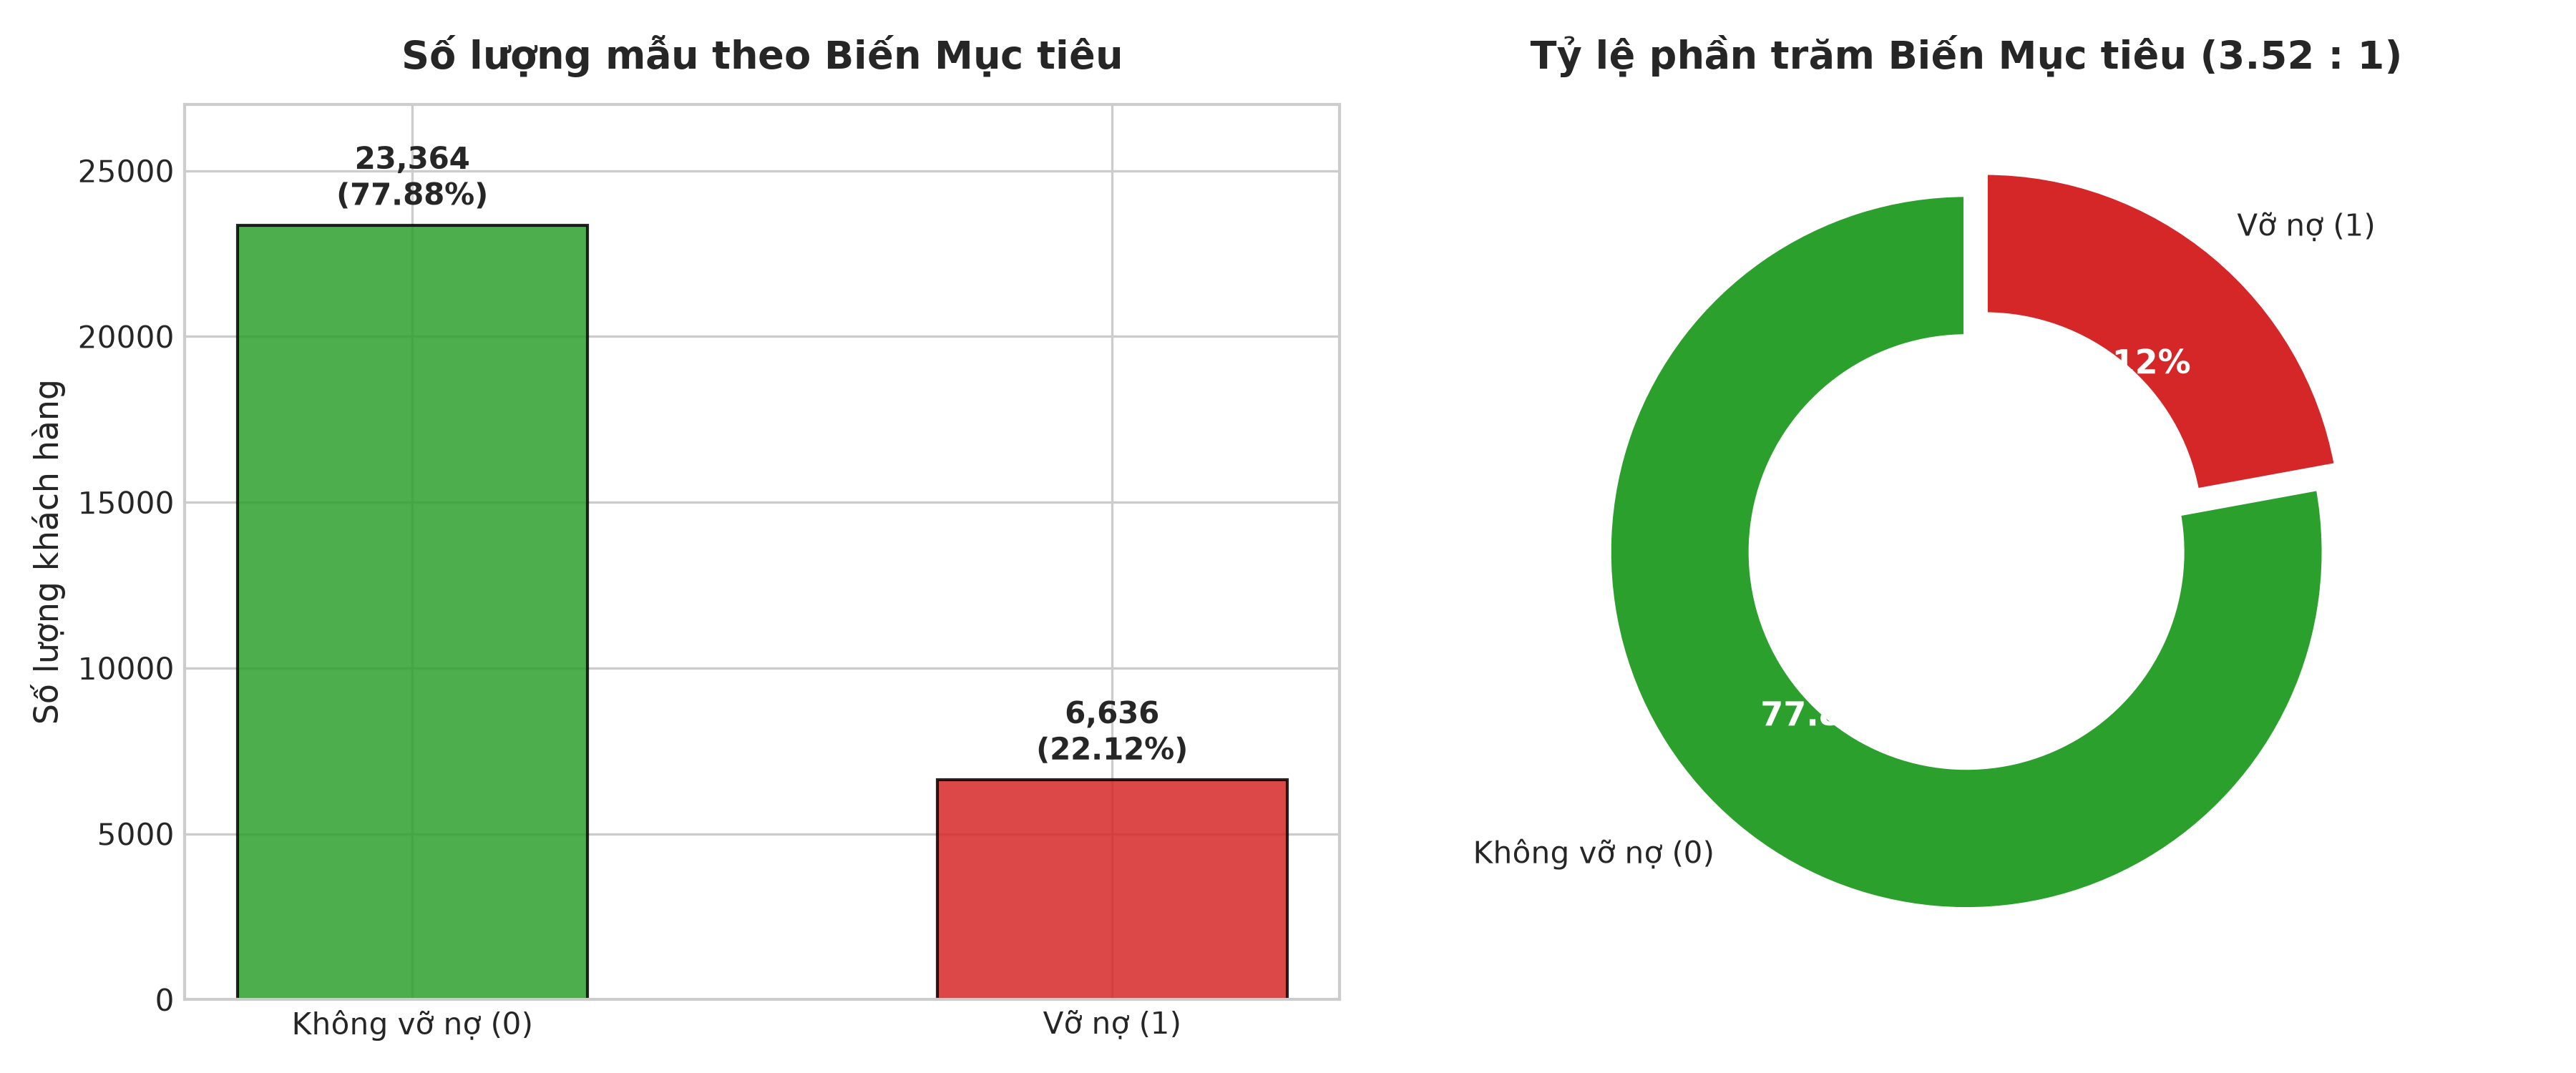

In [4]:
target_col = 'default.payment.next.month'
counts = df[target_col].value_counts()
pcts = df[target_col].value_counts(normalize=True) * 100
imbalance_ratio = counts[0] / counts[1]

target_summary = pd.DataFrame({
    'Số lượng (Counts)': counts,
    'Tỷ lệ (%)': pcts.round(2)
})
target_summary.index = ['Không vỡ nợ (0)', 'Vỡ nợ (1)']
display(target_summary)
print(f"Tỷ lệ Mất cân bằng Lớp (Imbalance Ratio 0 : 1): {imbalance_ratio:.2f} : 1")

# Hiển thị biểu đồ phân bố Target
fig_path = os.path.join('..', 'reports', 'figures', 'target_distribution.png')
if not os.path.exists(fig_path):
    fig_path = os.path.join('reports', 'figures', 'target_distribution.png')

if os.path.exists(fig_path):
    display(Image(filename=fig_path))


### Nhận xét Phần 3:
1. **Phân bố Lớp**:
   - Nhóm 0 (Không vỡ nợ): **23,364 khách hàng** (**77.88%**).
   - Nhóm 1 (Vỡ nợ): **6,636 khách hàng** (**22.12%**).
2. **Mức độ Mất cân bằng Lớp (Class Imbalance Ratio)**:
   - Tỷ lệ giữa lớp đa số (0) và lớp thiểu số (1) là **3.52 : 1**.
3. **Ảnh hưởng tới Đánh giá Mô hình Machine Learning sau này**:
   - Nếu một mô hình ML "ngây thơ" (Baseline Naive Model) luôn dự báo tất cả khách hàng là 0 (Không vỡ nợ), mô hình vẫn đạt Độ chính xác (Accuracy) lên tới **77.88%**.
   - Do đó, metric **Accuracy KHÔNG phù hợp** để làm chỉ số đánh giá chính cho đồ án này. Ở bước huấn luyện ML, cần bắt buộc sử dụng các chỉ số **ROC-AUC, PR-AUC, F1-Score, Precision, Recall** và chi phí phân loại sai (Cost-Sensitive Evaluation).


---
## 4. Thống kê Mô tả & Phân tích Đơn biến (Univariate Analysis)

Tiến hành thống kê mô tả cho các biến định lượng: `LIMIT_BAL`, `AGE`, `BILL_AMT1..6`, `PAY_AMT1..6` bao gồm:
- **Central Tendency**: Mean, Median (50%).
- **Dispersion**: Std, Min, Max, IQR (Q75 - Q25).
- **Shape**: Skewness (Độ lệch), Kurtosis (Độ nhọn).


,mean,std,min,25%,50%,75%,max,skewness,kurtosis
LIMIT_BAL,167484.32,129747.66,10000.00,50000.00,140000.00,240000.00,1000000.00,0.99,0.54
AGE,35.49,9.22,21.00,28.00,34.00,41.00,79.00,0.73,0.04
BILL_AMT1,51223.33,73635.86,-165580.00,3558.75,22381.50,67091.00,964511.00,2.66,9.81
BILL_AMT2,49179.08,71173.77,-69777.00,2984.75,21200.00,64006.25,983931.00,2.71,10.30
BILL_AMT3,47013.15,69349.39,-157264.00,2666.25,20088.50,60164.75,1664089.00,3.09,19.78
BILL_AMT4,43262.95,64332.86,-170000.00,2326.75,19052.00,54506.00,891586.00,2.82,11.31
BILL_AMT5,40311.40,60797.16,-81334.00,1763.00,18104.50,50190.50,927171.00,2.88,12.31
BILL_AMT6,38871.76,59554.11,-339603.00,1256.00,17071.00,49198.25,961664.00,2.85,12.27
PAY_AMT1,5663.58,16563.28,0.00,1000.00,2100.00,5006.00,873552.00,14.67,415.25
PAY_AMT2,5921.16,23040.87,0.00,833.00,2009.00,5000.00,1684259.00,30.45,1641.63


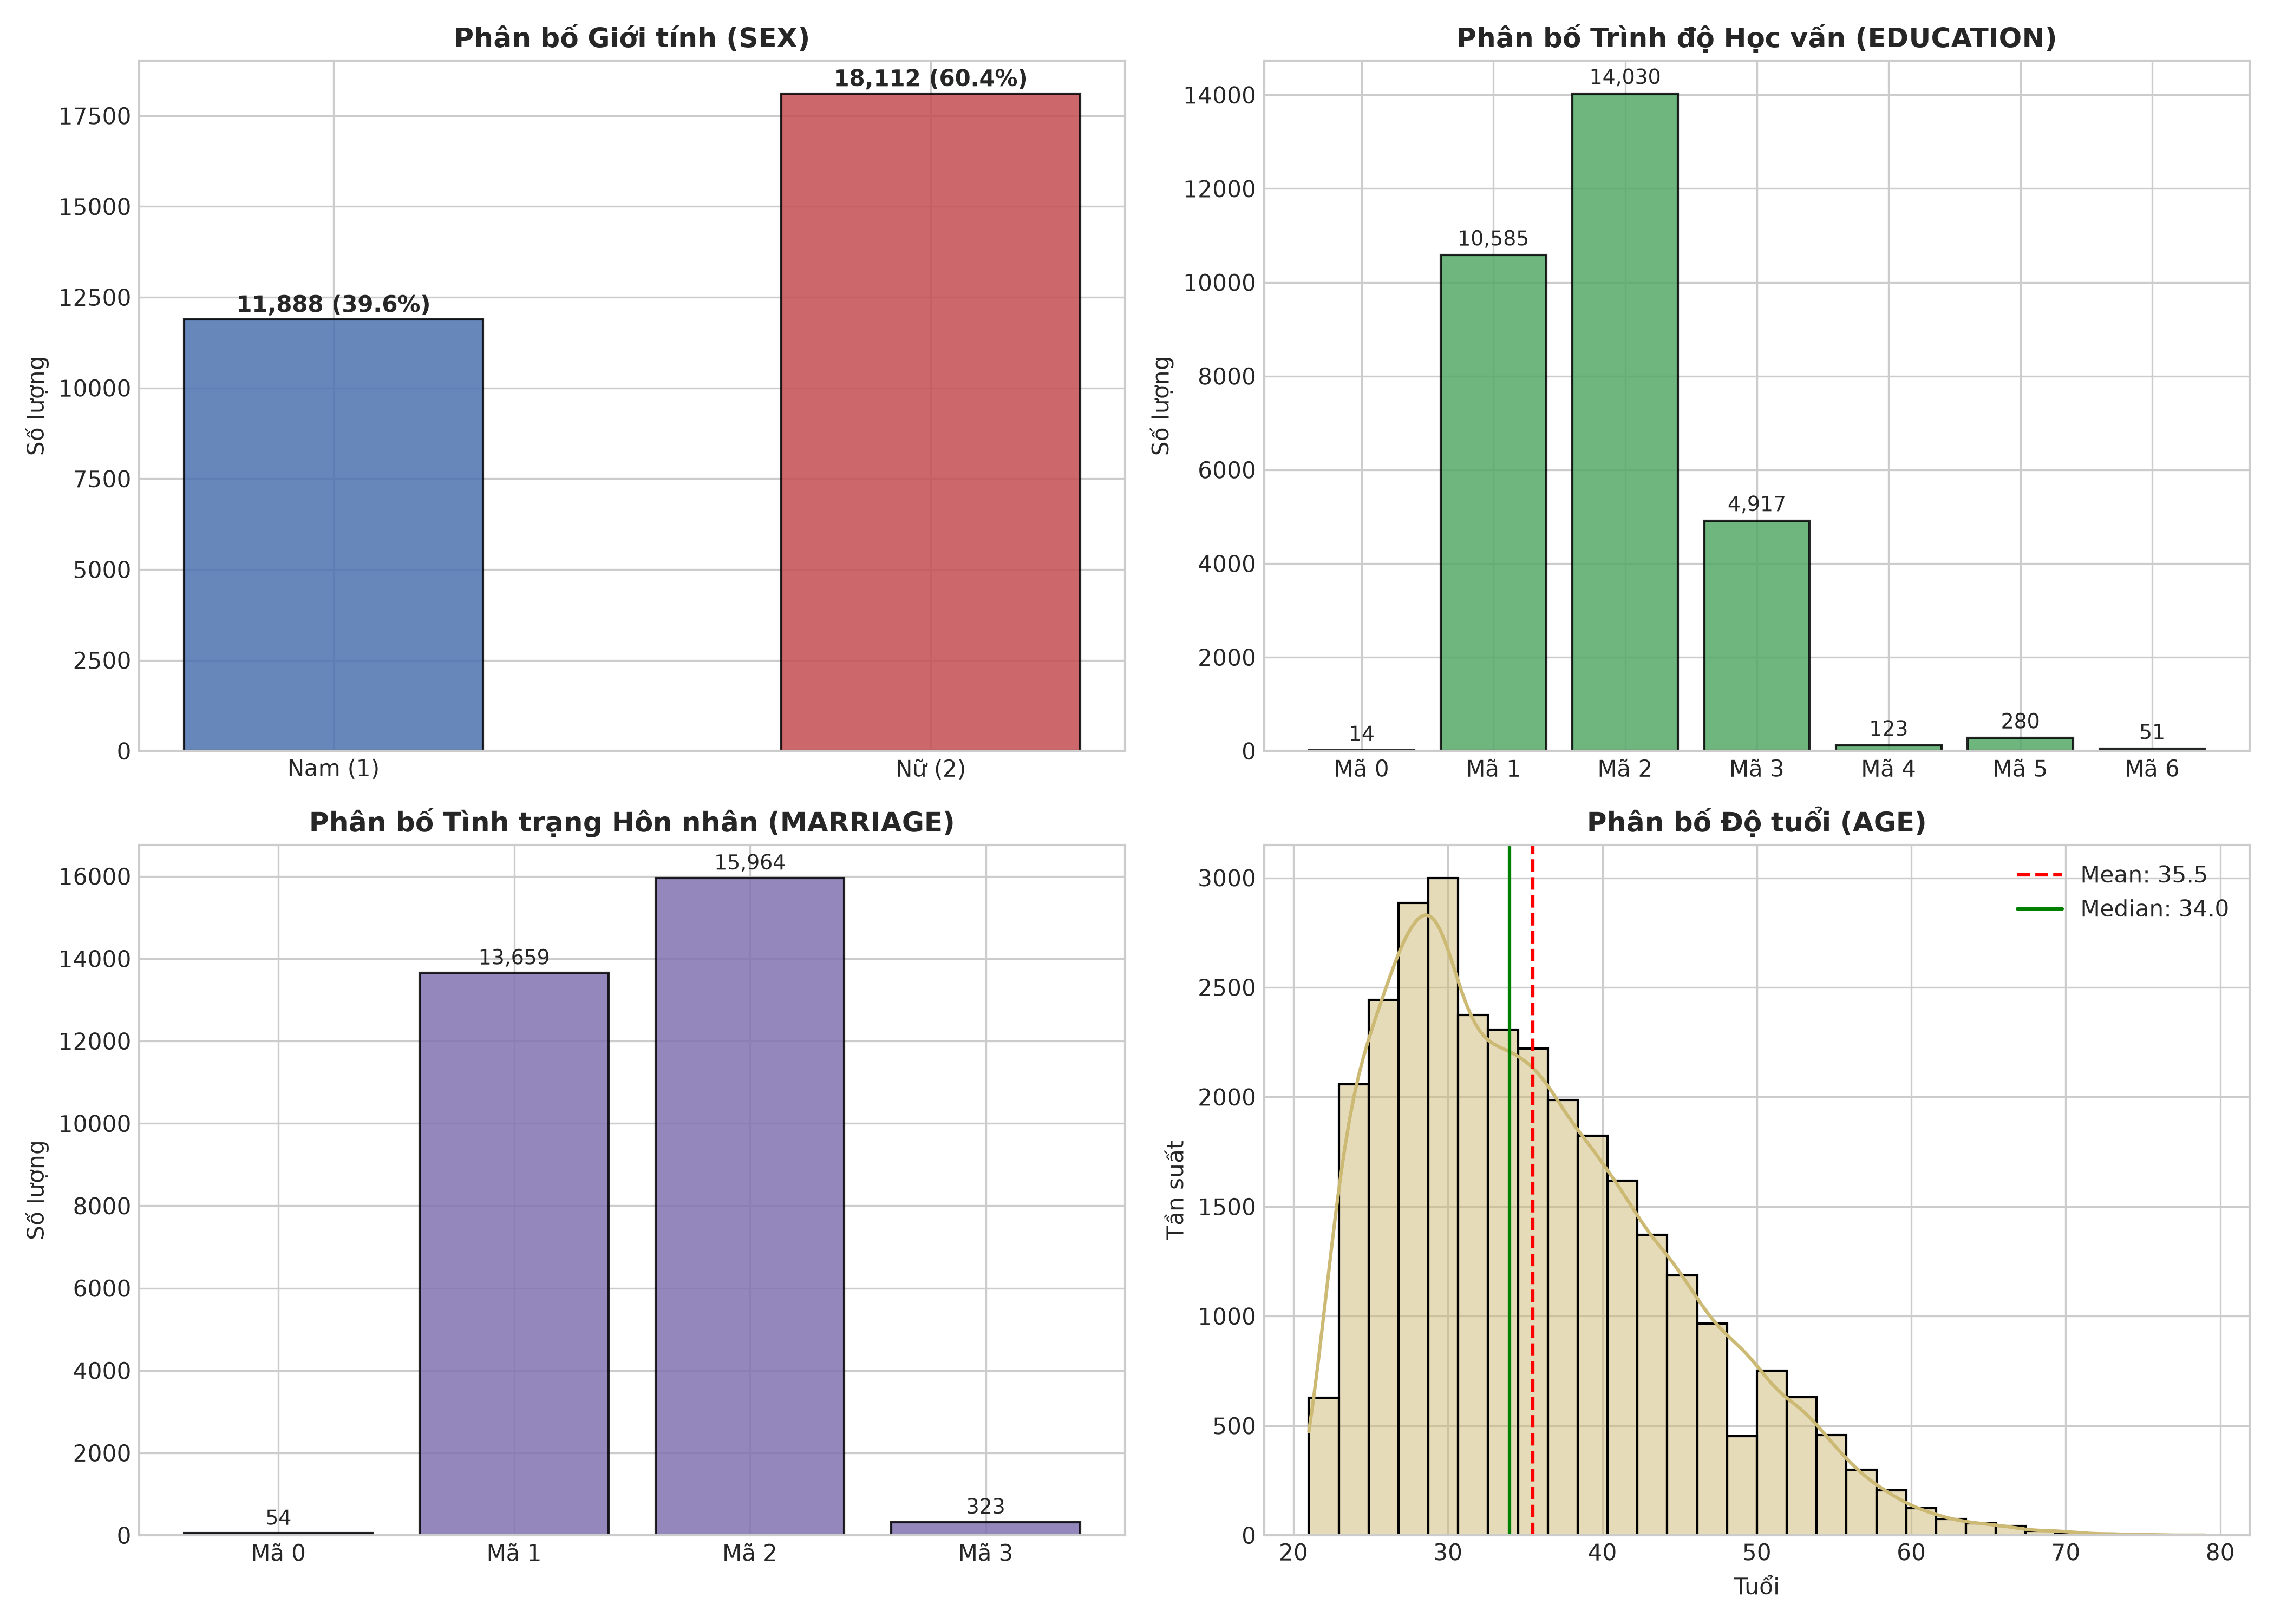

In [5]:
num_cols = ['LIMIT_BAL', 'AGE'] + [f'BILL_AMT{i}' for i in range(1, 7)] + [f'PAY_AMT{i}' for i in range(1, 7)]

num_stats = df[num_cols].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
num_stats['skewness'] = df[num_cols].skew()
num_stats['kurtosis'] = df[num_cols].kurt()

display(num_stats)

# Hiển thị biểu đồ phân bố biến Nhân khẩu học
fig_path = os.path.join('..', 'reports', 'figures', 'demographic_distribution.png')
if not os.path.exists(fig_path):
    fig_path = os.path.join('reports', 'figures', 'demographic_distribution.png')

if os.path.exists(fig_path):
    display(Image(filename=fig_path))


### Nhận xét Phần 4:
1. **Hạn mức tín dụng (`LIMIT_BAL`)**:
   - Giá trị trung bình: **167,484 NTD**, Trung vị: **140,000 NTD**, Nhỏ nhất: 10,000 NTD, Lớn nhất: 1,000,000 NTD.
   - Skewness = **0.99** (lệch phải nhẹ).
2. **Độ tuổi (`AGE`)**:
   - Độ tuổi trung bình: **35.49 tuổi**, Trung vị: **34.0 tuổi** (Dao động từ 21 đến 79 tuổi).
   - Phần lớn khách hàng thuộc độ tuổi lao động trẻ từ 25 đến 45 tuổi.
3. **Các biến Hóa đơn (`BILL_AMT1..6`) & Số tiền thanh toán (`PAY_AMT1..6`)**:
   - `BILL_AMT`: Trung bình khoảng 38,000 - 51,000 NTD, skewness từ 2.66 đến 3.09 (lệch phải vừa).
   - `PAY_AMT`: Trung bình khoảng 4,700 - 5,900 NTD, trung vị khoảng 1,500 - 2,100 NTD. Tuy nhiên, giá trị Max lên tới 1.68 triệu NTD!
   - Skewness của `PAY_AMT` từ **10.6 đến 30.5**, Kurtosis từ **167 đến 1641** -> Đây là phân bố có đuôi cực dày (Heavy-tailed distribution) và chứa nhiều giá trị ngoại biệt cực đại (Extreme Outliers).


---
## 5. Phân tích Đa biến & Mối quan hệ với Biến Mục tiêu (Bivariate & Default Rate Analysis)

Phần này phân tích tỷ lệ vỡ nợ (Default Rate %) theo các nhóm nhân khẩu học và trạng thái lịch sử thanh toán, đồng thời so sánh phân bố giữa lớp 0 và lớp 1 bằng Boxplot.


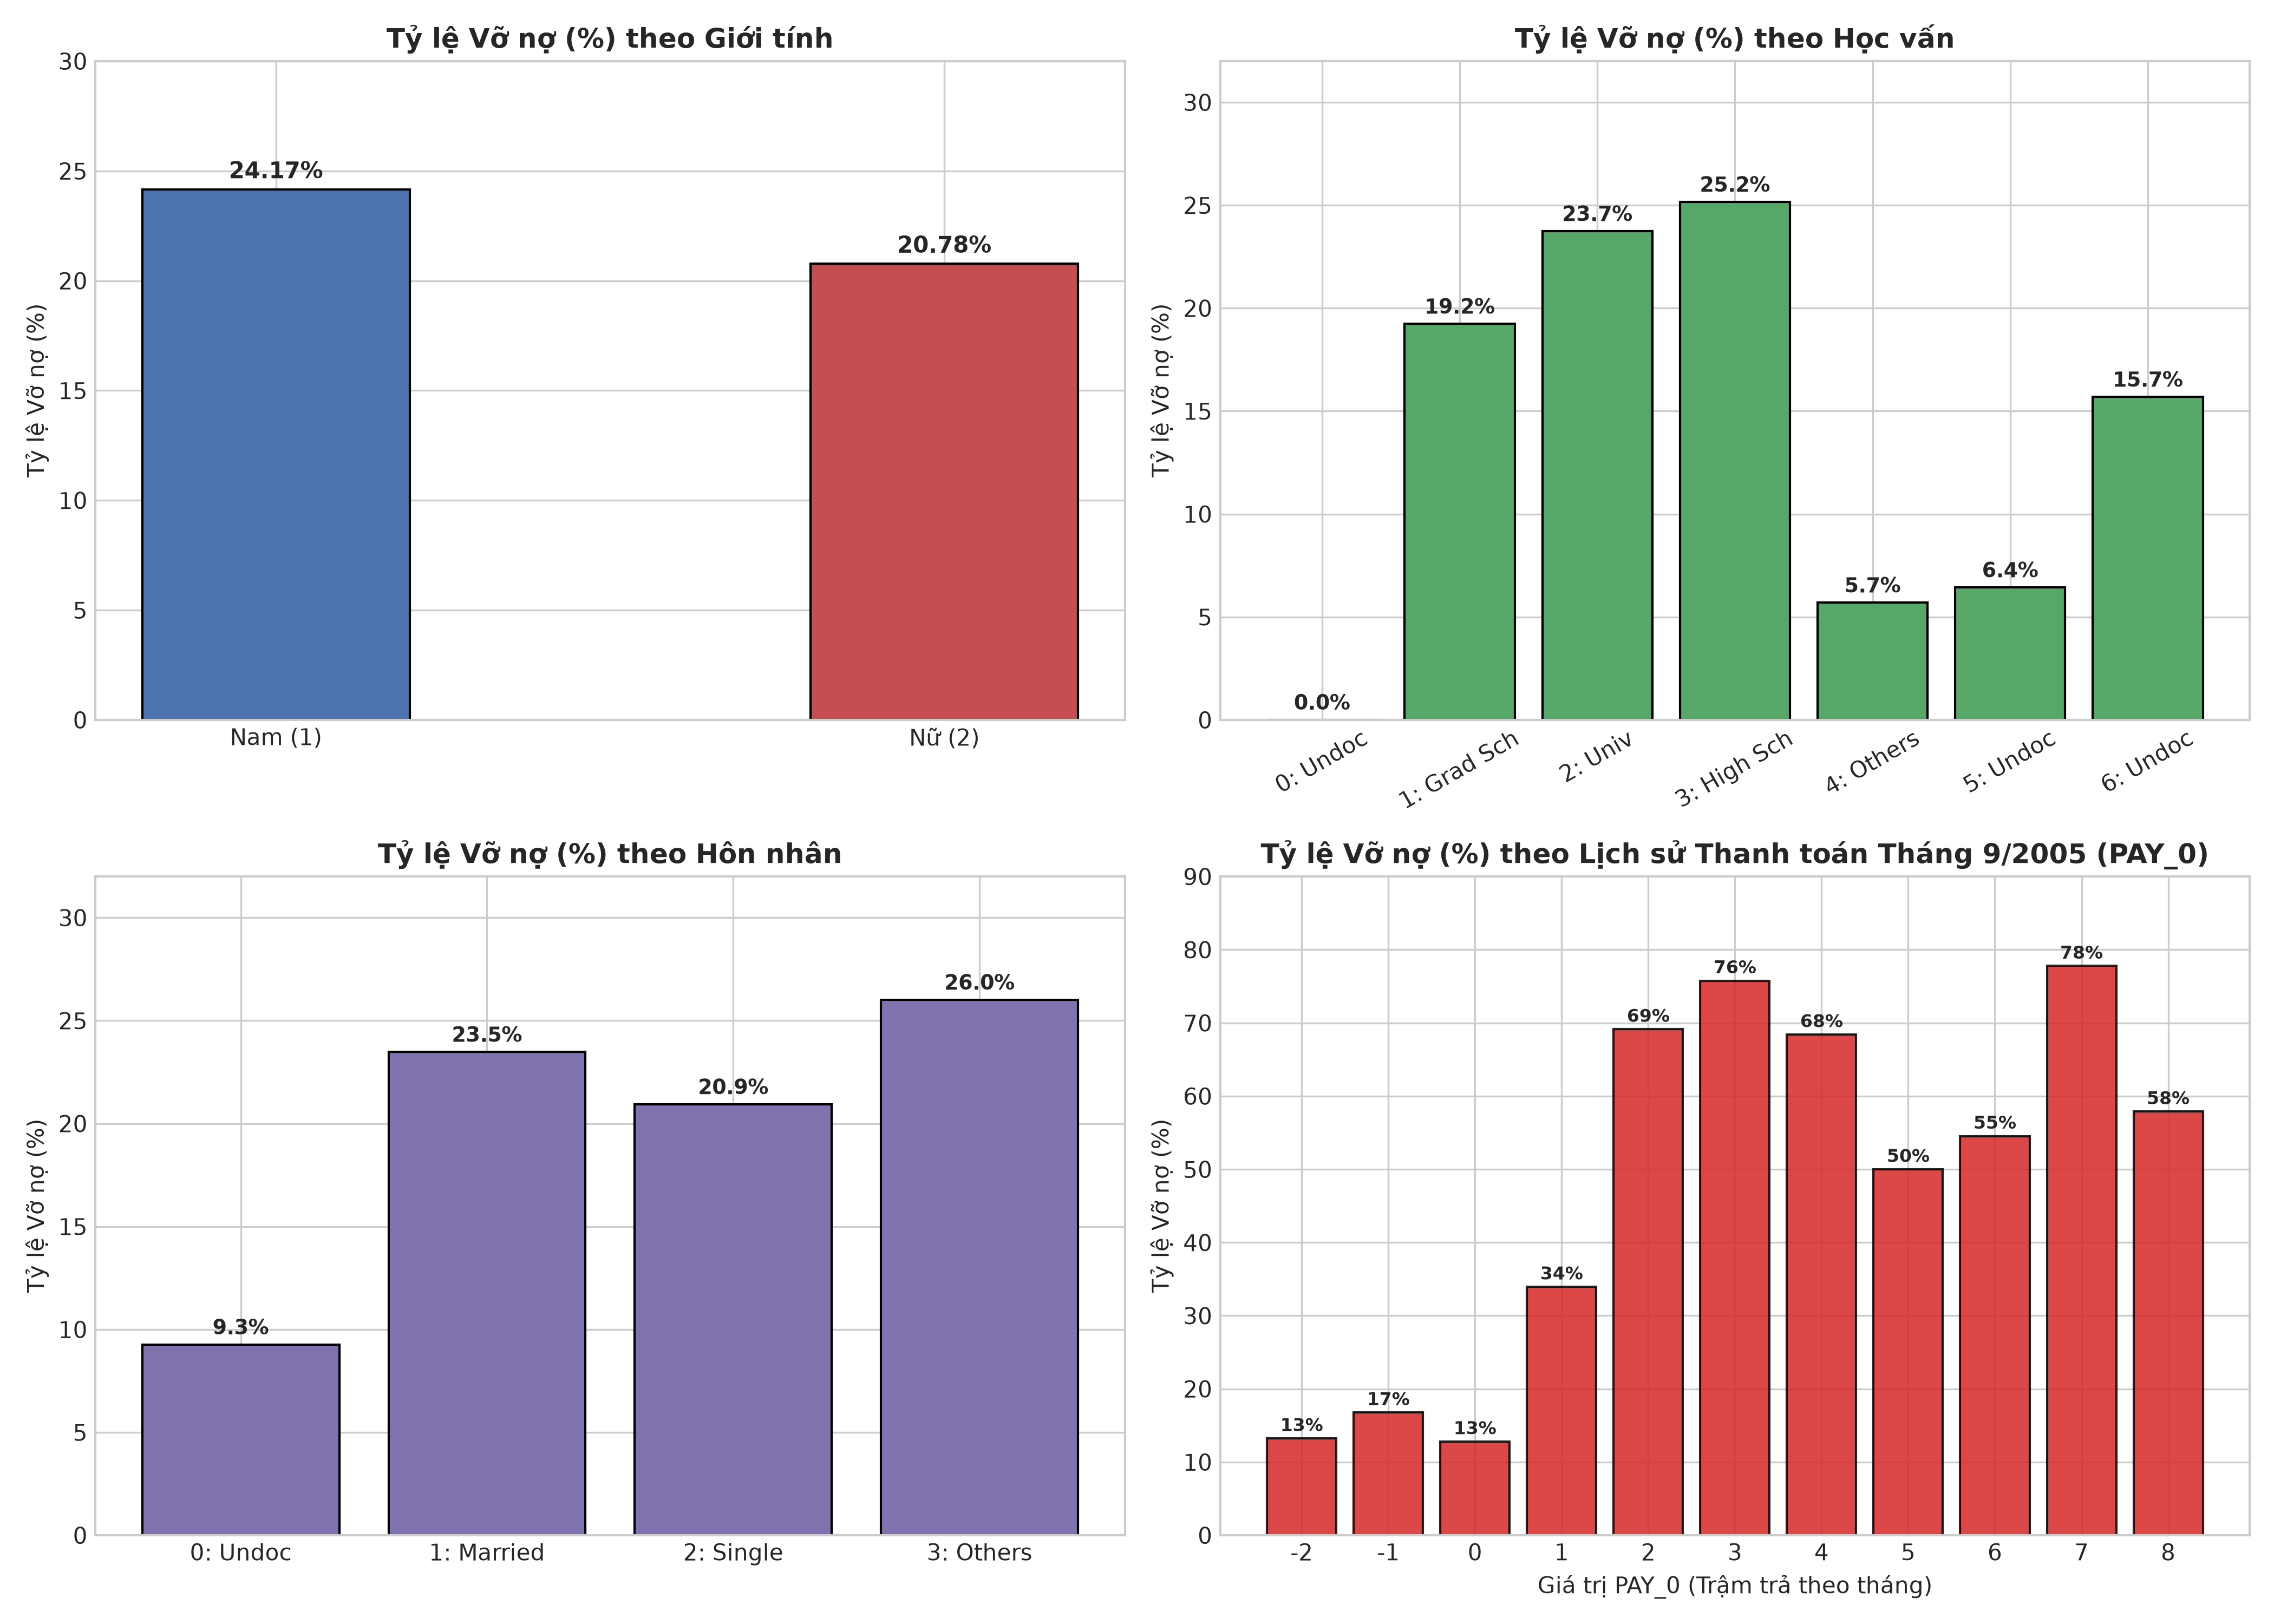

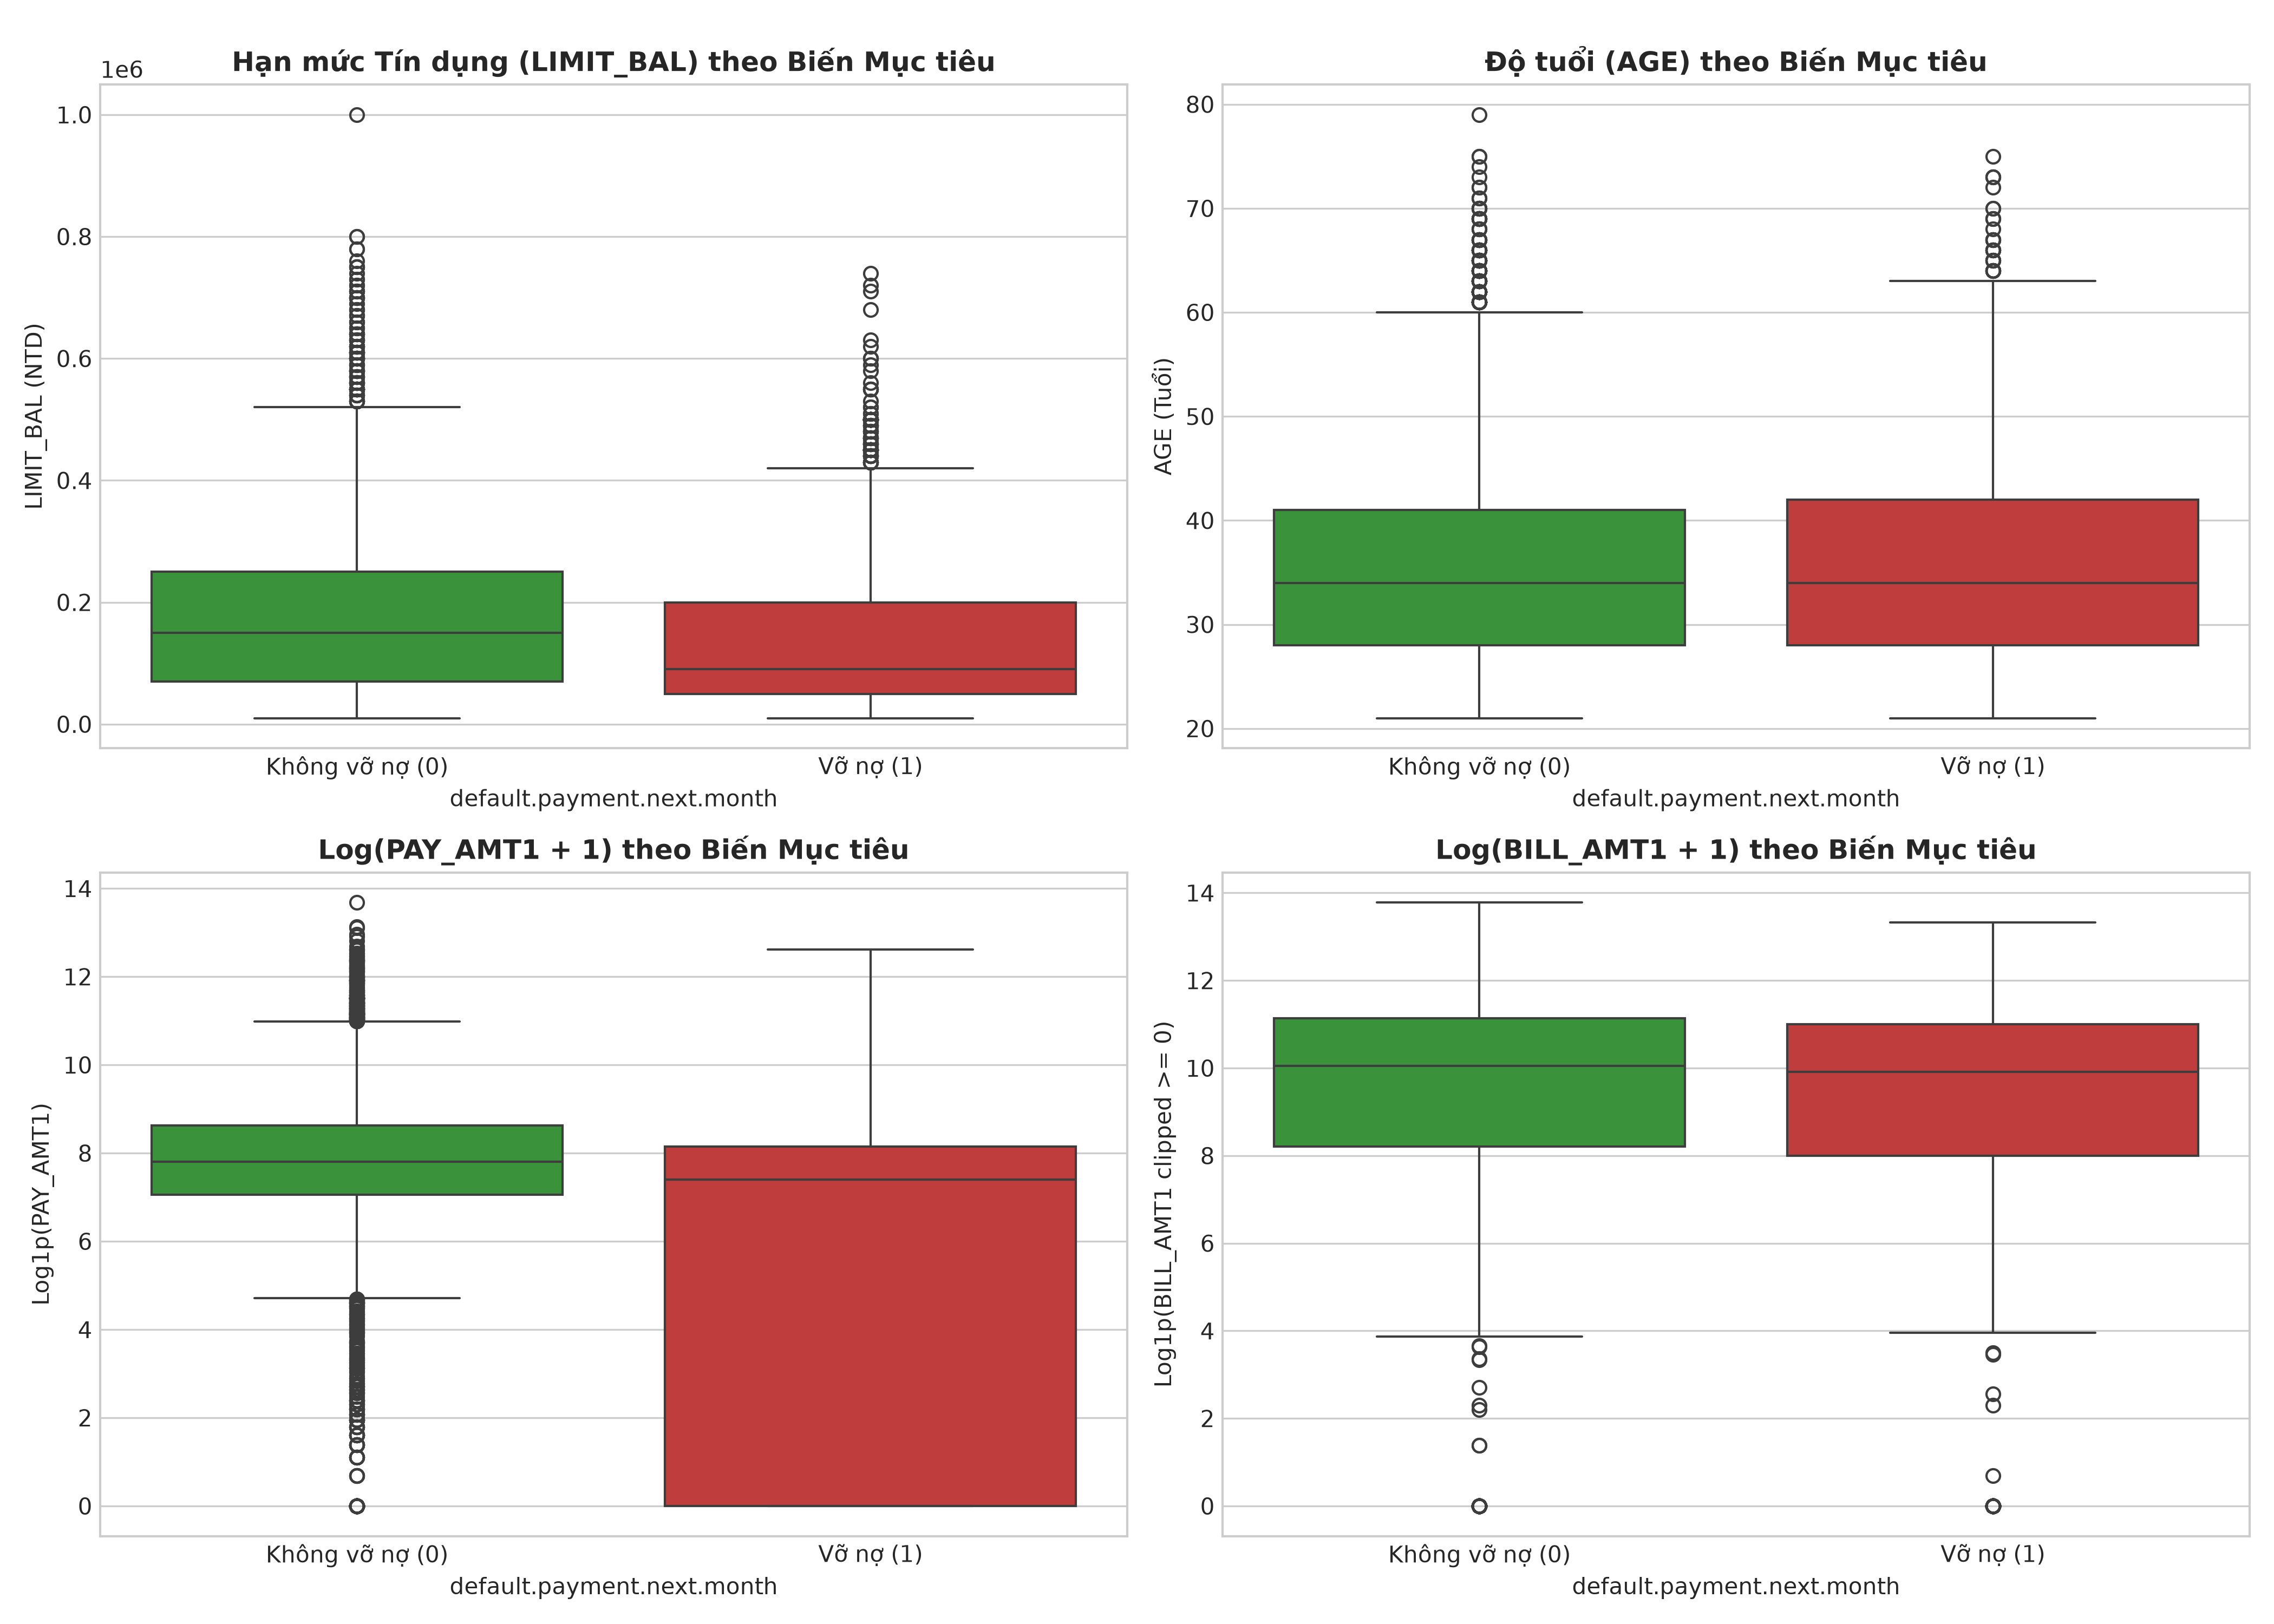

In [6]:
# Hiển thị biểu đồ Tỷ lệ vỡ nợ theo nhóm
fig_path1 = os.path.join('..', 'reports', 'figures', 'default_rates_by_groups.png')
if not os.path.exists(fig_path1):
    fig_path1 = os.path.join('reports', 'figures', 'default_rates_by_groups.png')
if os.path.exists(fig_path1):
    display(Image(filename=fig_path1))

# Hiển thị Boxplots so sánh với Target
fig_path2 = os.path.join('..', 'reports', 'figures', 'boxplots_by_target.png')
if not os.path.exists(fig_path2):
    fig_path2 = os.path.join('reports', 'figures', 'boxplots_by_target.png')
if os.path.exists(fig_path2):
    display(Image(filename=fig_path2))


### Nhận xét Phần 5:
1. **Mối quan hệ Giới tính (SEX) với Vỡ nợ**:
   - Khách hàng Nam (SEX=1) có tỷ lệ vỡ nợ **24.17%**, cao hơn đáng kể so với Nữ giới (SEX=2) là **20.78%**.
2. **Mối quan hệ Trình độ Học vấn (EDUCATION) với Vỡ nợ**:
   - Nhóm có trình độ Học vấn Cấp 3 (EDUCATION=3) có tỷ lệ vỡ nợ cao nhất (**25.16%**), tiếp theo là Đại học (EDUCATION=2) với **23.73%** và Cao học/Học viện (EDUCATION=1) là **19.23%**.
3. **Mối quan hệ Hôn nhân (MARRIAGE) với Vỡ nợ**:
   - Nhóm Hôn nhân khác/Ly hôn (MARRIAGE=3) có tỷ lệ vỡ nợ **26.01%**, nhóm Đã kết hôn (MARRIAGE=1) là **23.47%**, cao hơn nhóm Độc thân (MARRIAGE=2) là **20.93%**.
4. **Tác động cực kỳ mạnh mẽ của Trạng thái Thanh toán Tháng 9/2005 (`PAY_0`)**:
   - Khách hàng trả đúng hạn/xoay vòng (`PAY_0 <= 0`) có tỷ lệ vỡ nợ chỉ từ **12.8% - 16.8%**.
   - Ngay khi khách hàng bị trậm trả 1 tháng (`PAY_0 = 1`), tỷ lệ vỡ nợ tăng vọt lên **33.95%**.
   - Nếu trậm trả 2 tháng (`PAY_0 = 2`), tỷ lệ vỡ nợ lên tới **69.14%**! Điều này cho thấy `PAY_0` là đặc trưng có sức mạnh dự báo rủi ro tín dụng hàng đầu.


---
## 6. Phân tích Tương quan & Đa cộng tuyến (Correlation & Multicollinearity Analysis)

Ma trận tương quan Pearson giữa 24 biến độc lập và biến mục tiêu `default.payment.next.month`.


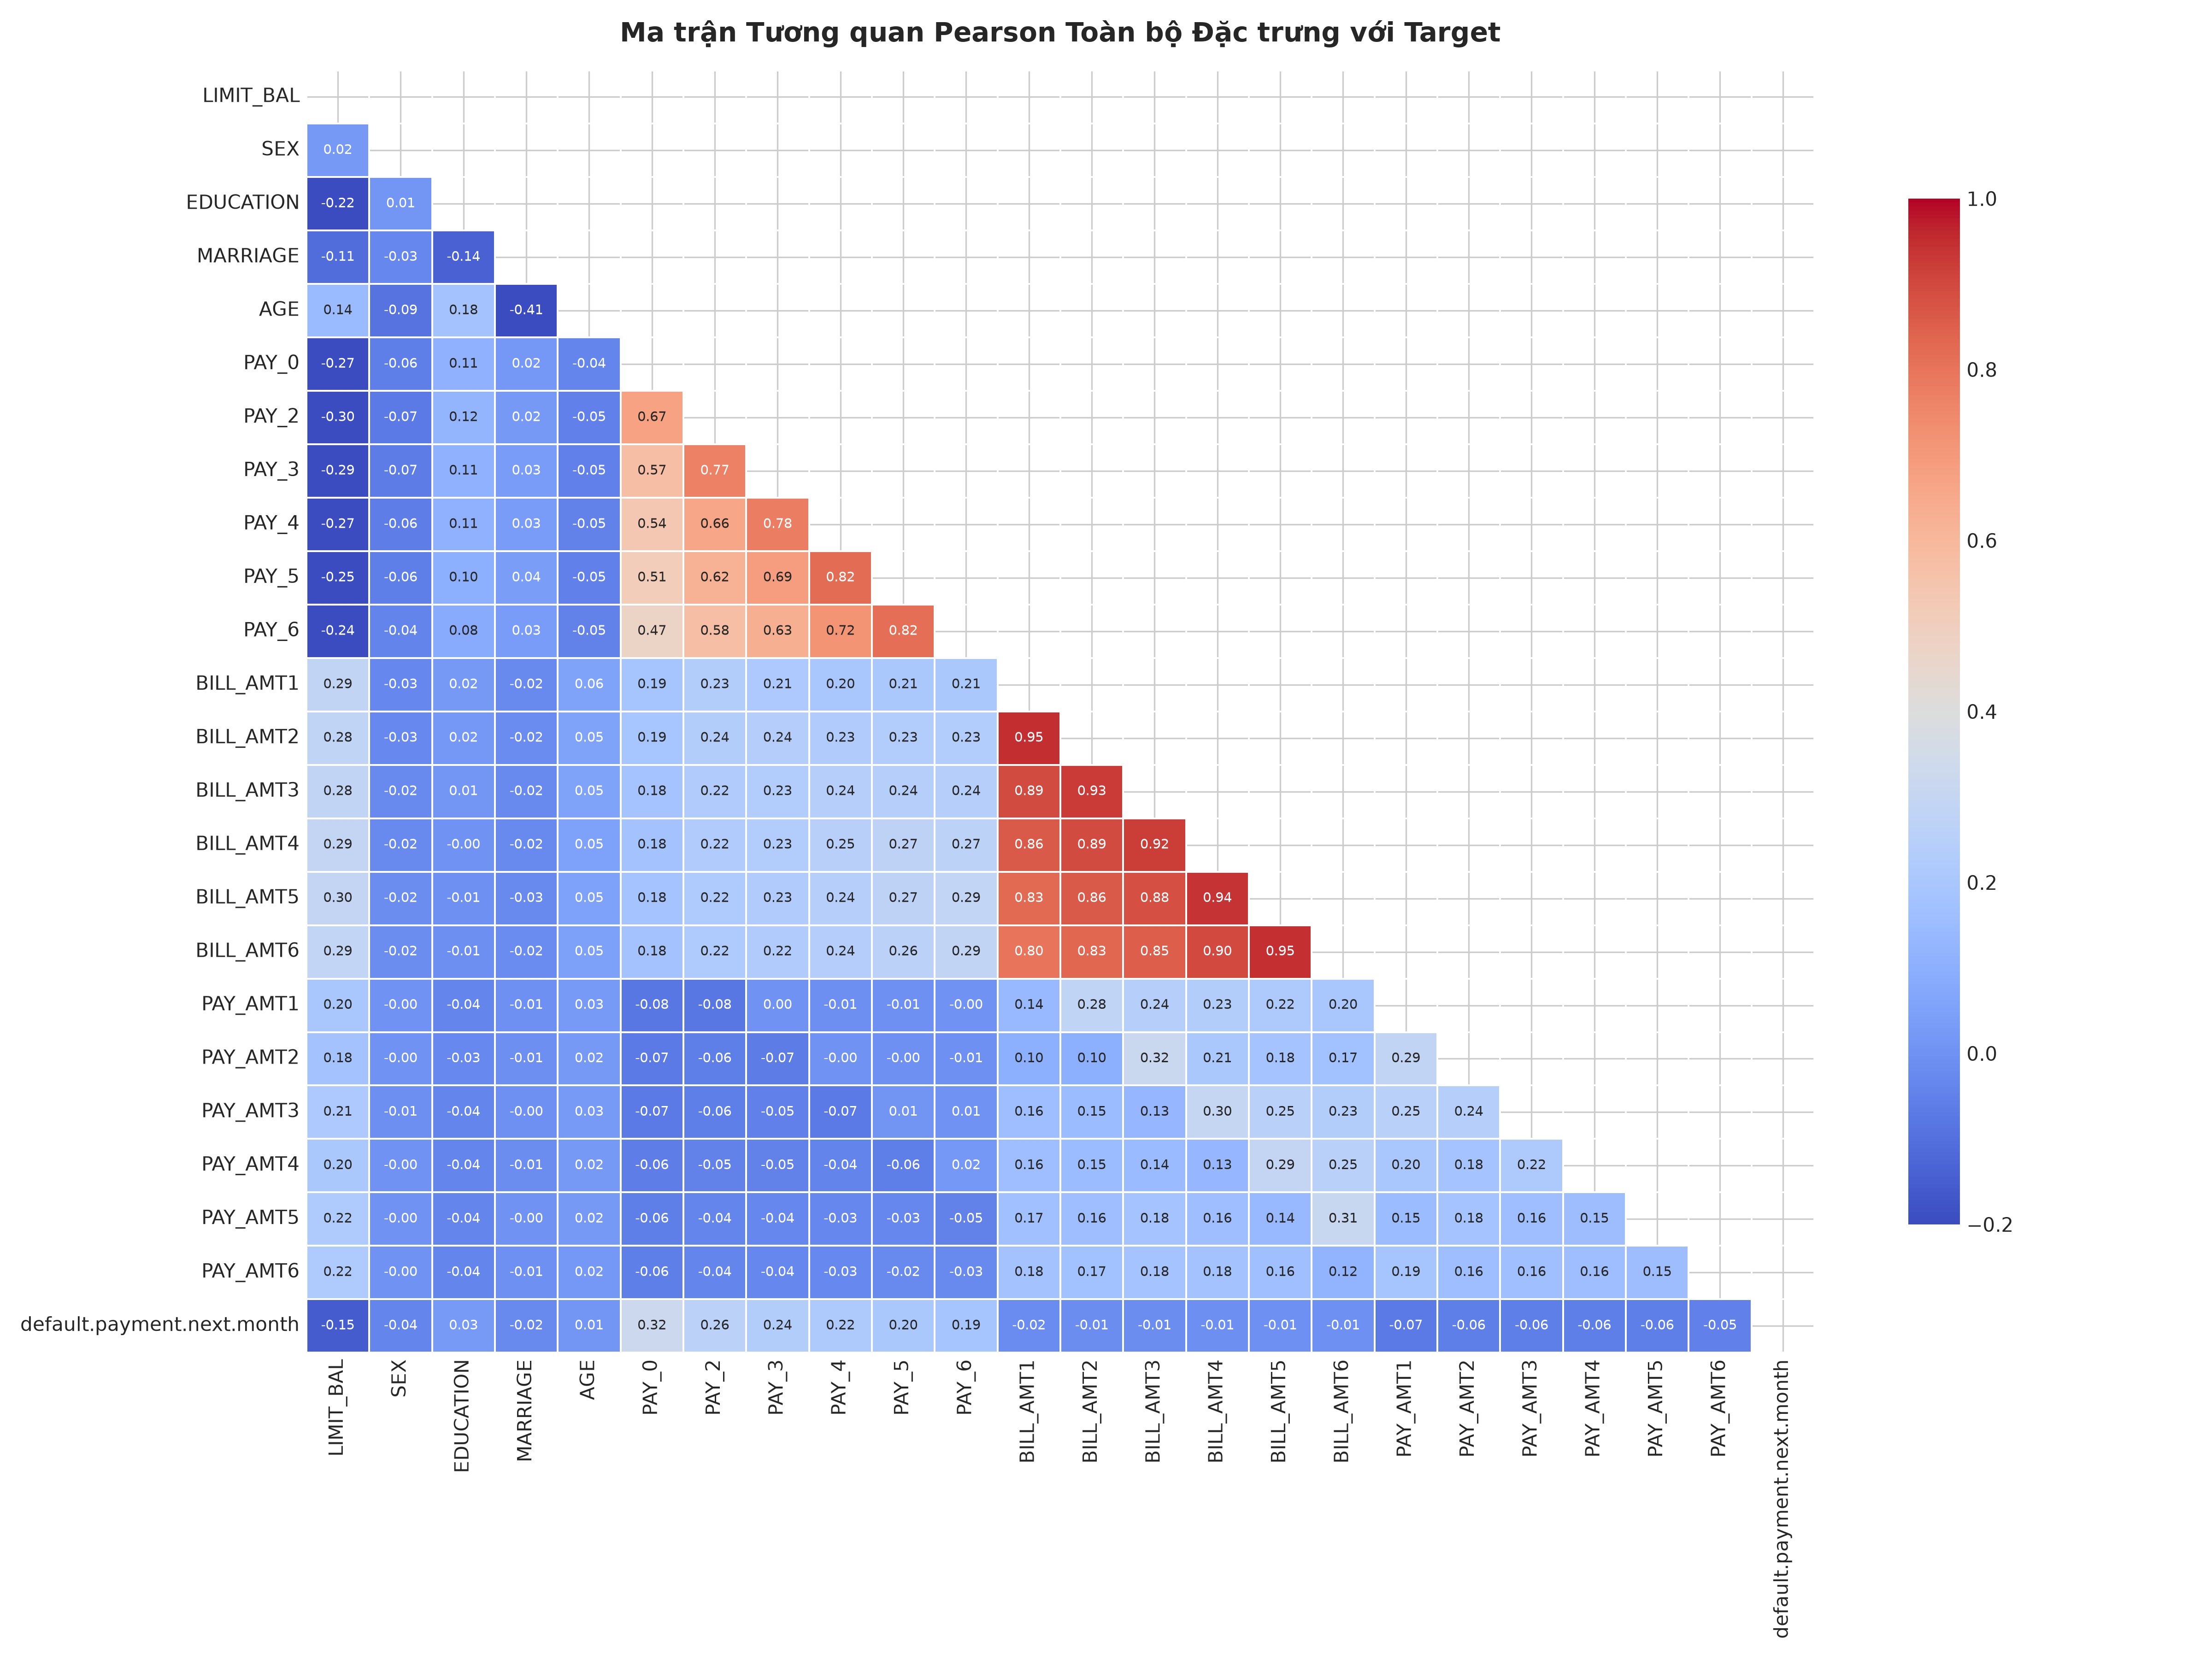

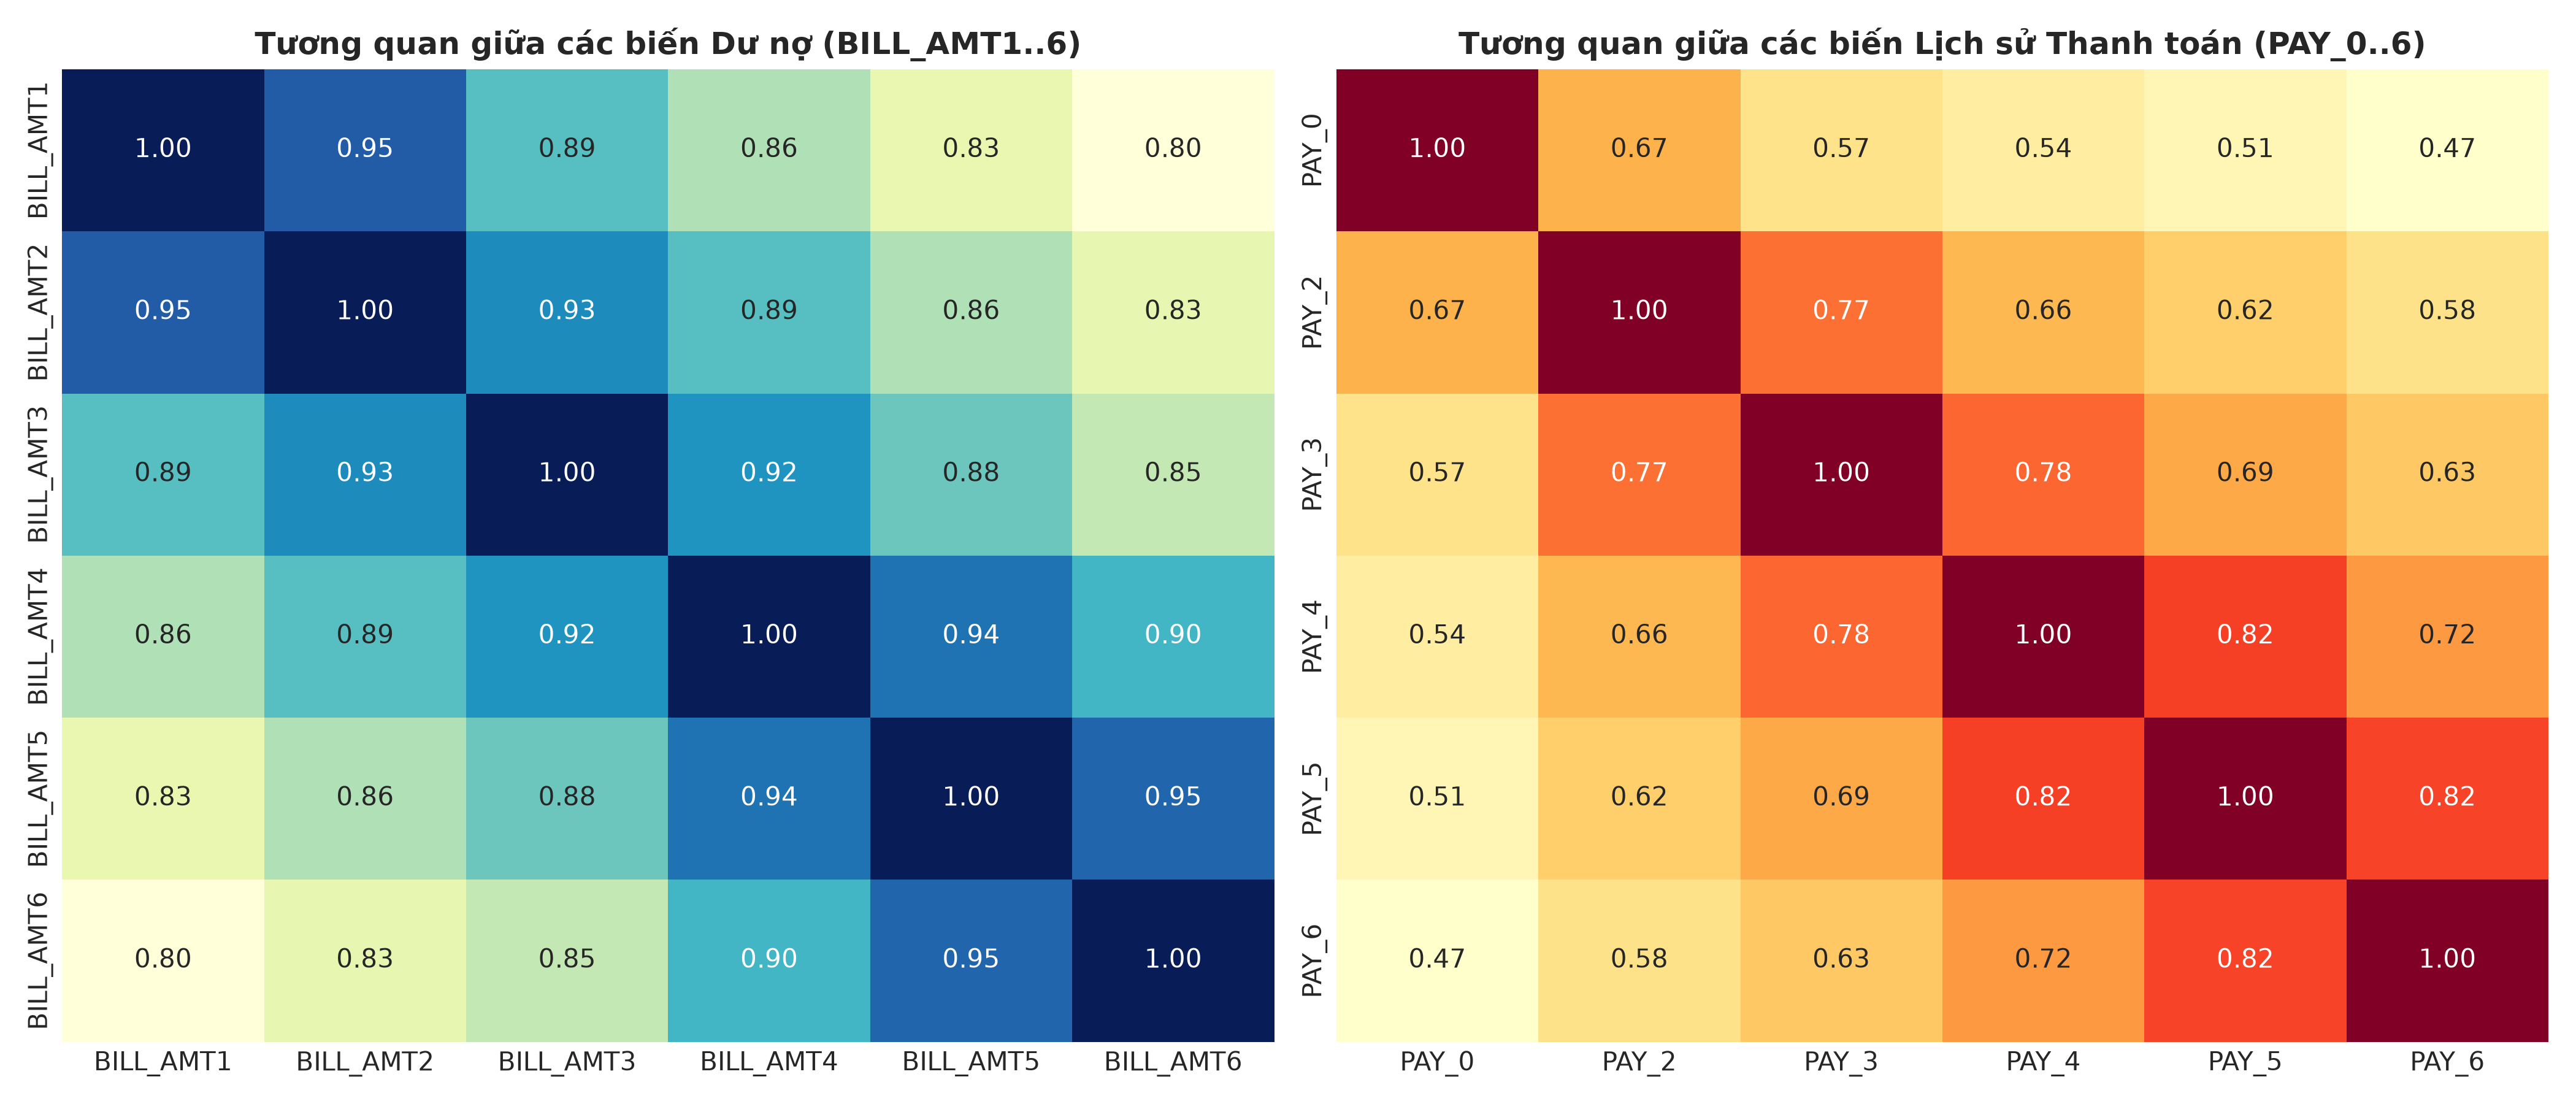

In [7]:
# Hiển thị Ma trận Tương quan Pearson Toàn bộ Đặc trưng
fig_path1 = os.path.join('..', 'reports', 'figures', 'correlation_heatmap.png')
if not os.path.exists(fig_path1):
    fig_path1 = os.path.join('reports', 'figures', 'correlation_heatmap.png')
if os.path.exists(fig_path1):
    display(Image(filename=fig_path1))

# Hiển thị Đa cộng tuyến giữa BILL_AMT và PAY
fig_path2 = os.path.join('..', 'reports', 'figures', 'multicollinearity_heatmap.png')
if not os.path.exists(fig_path2):
    fig_path2 = os.path.join('reports', 'figures', 'multicollinearity_heatmap.png')
if os.path.exists(fig_path2):
    display(Image(filename=fig_path2))


### Nhận xét Phần 6:
1. **Tương quan với Biến Mục tiêu (Target Correlation)**:
   - `PAY_0` có tương quan dương mạnh nhất với vỡ nợ ($r = +0.325$), nối tiếp bởi `PAY_2` ($r = +0.264$), `PAY_3` ($r = +0.235$), `PAY_4` ($r = +0.217$).
   - `LIMIT_BAL` có tương quan âm ($r = -0.154$), phản ánh khách hàng được cấp hạn mức càng cao thì rủi ro vỡ nợ càng thấp.
   - Các biến `BILL_AMT1..6` có tương quan tuyến tính với Target rất yếu ($|r| < 0.02$).
2. **Hiện tượng Đa cộng tuyến nghiêm trọng (High Multicollinearity)**:
   - Các biến dư nợ hóa đơn `BILL_AMT1..6` giữa các tháng liên tiếp tương quan cực kỳ cao: $r(	ext{BILL\_AMT1}, 	ext{BILL\_AMT2}) = 0.951$, $r(	ext{BILL\_AMT4}, 	ext{BILL\_AMT5}) = 0.940$.
   - Các biến lịch sử thanh toán `PAY_0..6` cũng tương quan khá cao ($r = 0.72 - 0.82$).
   - **Tác động ML**: Đa cộng tuyến cao làm mất ổn định hệ số regression trong các mô hình tuyến tính (Logistic Regression) và làm tăng biến động trọng số. Ở bước Preprocessing, cần xem xét biến đổi tạo feature tổng hợp (dư nợ trung bình, tỷ lệ sử dụng hạn mức `BILL_AMT / LIMIT_BAL`) hoặc áp dụng kỹ thuật giảm chiều dữ liệu/chọn lọc đặc trưng.


---
## 7. Đánh giá Rủi ro ML & Đề xuất cho bước Preprocessing (ML Risk Assessment & Recommendations)

### 7.1. Đánh giá Rủi ro Rò rỉ Dữ liệu (Data Leakage Audit)
- **Cột ID**: Cột `ID` là mã thứ tự định danh khách hàng, không chứa thông tin tài chính và không có giá trị tiên đoán. Bắt buộc loại bỏ khi huấn luyện ML.
- **Tính Thời gian (Temporal Consistency)**: Các biến `PAY_0..6`, `BILL_AMT1..6`, `PAY_AMT1..6` ghi nhận hành vi từ Tháng 4/2005 đến Tháng 9/2005. Biến mục tiêu đo lường hành vi vỡ nợ trong Tháng 10/2005. Thứ tự thời gian hoàn toàn hợp lệ, **KHÔNG phát hiện rò rỉ dữ liệu thời gian (No Temporal Data Leakage)**.

---
## Những vấn đề cần xử lý ở bước Preprocessing (CHỈ ĐỀ XUẤT)

> [!IMPORTANT]
> Đây là mục tổng hợp đề xuất các bước xử lý dữ liệu cho Giai đoạn Preprocessing tiếp theo. Trong Notebook này, chúng tôi **CHƯA thực hiện bất kỳ thao tác biến đổi dữ liệu nào** để đảm bảo tuân thủ yêu cầu ĐATN.

1. **Loại bỏ đặc trưng không tiên đoán (`ID`)**:
   - Loại bỏ cột `ID` khỏi tập đặc trưng huấn luyện.
2. **Xử lý Dòng trùng lặp (Duplicate Rows)**:
   - Loại bỏ 35 dòng dữ liệu trùng lặp hoàn toàn thuộc tính khách hàng để tránh thiên vị mẫu.
3. **Xử lý Giá trị Danh mục chưa quy ước (Undocumented Codes)**:
   - Ở biến `EDUCATION`: Gom các mã `0, 5, 6` về nhóm `4 (Others)` hoặc tạo nhóm `0 (Unknown)`.
   - Ở biến `MARRIAGE`: Gom mã `0` về nhóm `3 (Others)` hoặc nhóm `0 (Unknown)`.
4. **Biến đổi Phân bố Lệch & Chuẩn hóa Dữ liệu (Scaling & Transformation)**:
   - Nhóm `PAY_AMT1..6` có skewness > 10 và kurtosis cực cao: Sử dụng phép biến đổi phi tuyến như `Log1p` hoặc `Yeo-Johnson` kết hợp với `RobustScaler` hoặc `StandardScaler` nhằm giảm ảnh hưởng của outliers cực đại.
5. **Kỹ thuật Kỹ thuật Đặc trưng (Feature Engineering)**:
   - Để giải quyết hiện tượng đa cộng tuyến của `BILL_AMT1..6`, đề xuất tạo các đặc trưng tổng hợp giàu ý nghĩa tài chính:
     + `UTILIZATION_RATE`: Tỷ lệ sử dụng hạn mức ($	ext{BILL\_AMT1} / 	ext{LIMIT\_BAL}$).
     + `MEAN_BILL_AMT`: Dư nợ trung bình 6 tháng.
     + `MEAN_PAY_AMT`: Số tiền trả trung bình 6 tháng.
     + `PAY_RATIO`: Tỷ lệ thanh toán trên dư nợ ($	ext{PAY\_AMT} / (	ext{BILL\_AMT} + 1)$).
     + `MAX_PAY_DELAY`: Số tháng trậm trả tối đa trong 6 tháng.
6. **Xử lý Mất cân bằng Lớp (Class Imbalance Handling)**:
   - Do tỷ lệ mất cân bằng là 3.52:1 (22.12% vỡ nợ), ở bước huấn luyện mô hình ML sẽ áp dụng:
     + Tham số `class_weight='balanced'` đối với Logistic Regression, Random Forest, XGBoost.
     + Kỹ thuật lấy mẫu lại (Resampling): SMOTE / Random Under-Sampling trên tập Train (nếu cần).
     + Sử dụng chỉ số đánh giá ROC-AUC và PR-AUC thay cho Accuracy.
